In [1]:
import numpy as np
import jax
import jax.numpy as jnp
from jax.example_libraries import stax, optimizers
import matplotlib.pyplot as plt
from matplot2tikz import save
import pyvista as pv
import pinns 
import datetime
import jax.scipy.optimize
import jax.flatten_util
import scipy
import scipy.optimize
import random

rnd_key = jax.random.PRNGKey(1234)
np.random.seed(14124)

In [2]:
jax.config.update("jax_enable_x64", False)
print("Devices: ", jax.devices())
dev = jax.devices('gpu')[0] if jax.device_count()>1 and len(jax.devices('gpu'))>0 else jax.devices('cpu')[0]
dev = jax.devices('gpu')[0]
print(dev)


Devices:  [CudaDevice(id=0)]
cuda:0


In [3]:
def create_quarter_annulus(r_inner, r_outer, angle_start, angle_end):
    """
    Create a quarter annulus NURBS patch.
    
    Parameters:
    - r_inner: inner radius
    - r_outer: outer radius
    - angle_start: starting angle in radians
    - angle_end: ending angle in radians
    
    Returns:
    - PatchNURBS geometry
    """
    # Define B-spline bases (3D geometry with thin z-direction)
    basis_radial = pinns.functions.BSplineBasisJAX(np.array([-1, 0, 1]), 2)
    basis_angular = pinns.functions.BSplineBasisJAX(np.array([-1, 1]), 2)
    basis_z = pinns.functions.BSplineBasisJAX(np.array([-1, 1]), 1)  # Linear in z
    
    # Control points array [radial_points, angular_points, z_points, spatial_dim]
    pts = np.zeros([4, 3, 2, 3])
    weights = np.ones([4, 3, 2])
    
    # Calculate angle properties
    angle_mid = (angle_start + angle_end) / 2
    angle_span = angle_end - angle_start
    
    # For NURBS circular arc, we need special weighting
    # The middle control point weight for a circular arc
    a = np.pi/2 - angle_span/2
    w_mid = np.sin(a)
    
    # Radii for the 4 control points (quadratic in radial direction)
    rs = np.linspace(r_inner, r_outer, 4)
    
    # Define the angular control points (in local coordinates)
    # Start angle
    pts_angular_local = np.array([
        [np.cos(-angle_span/2), np.sin(-angle_span/2), 0],  # Start
        [1/np.sin(a), 0, 0],                                 # Middle (extended for NURBS)
        [np.cos(angle_span/2), np.sin(angle_span/2), 0]     # End
    ])
    
    # Create control points for each radius at z=0
    for i, r in enumerate(rs):
        pts[i, :, 0, :2] = r * pts_angular_local[:, :2]
        pts[i, :, 0, 2] = 0.0  # Bottom layer at z=0
    
    # Copy xy coordinates to z=1 layer and set z=1 for thickness
    pts[:, :, 1, :2] = pts[:, :, 0, :2]  # Same xy coordinates
    pts[:, :, 1, 2] = 1.0  # Top layer at z=1
    
    # Set the middle control point weights for NURBS circular representation
    weights[:, 1, :] = w_mid
    
    # Create the NURBS patch (3D geometry, dimension is 3)
    geom = pinns.geometry.PatchNURBS(
        [basis_radial, basis_angular, basis_z], pts, weights, 0, 3)
    
    # Rotate to the correct position
    rotation_angle = angle_mid
    geom.rotate((0, 0, rotation_angle))
    
    return geom

geoms = {}

# Patch 1: r in [1,2], angle [0, π/4]
geoms['patch_1'] = create_quarter_annulus(1.0, 2.0, 0, np.pi/4)

# Patch 2: r in [2,3], angle [0, π/4]
geoms['patch_2'] = create_quarter_annulus(2.0, 3.0, 0, np.pi/4)

# Patch 3: r in [2,3], angle [π/4, π/2]
geoms['patch_3'] = create_quarter_annulus(2.0, 3.0, np.pi/4, np.pi/2)

print("Created 3 geometry patches forming L-shape topology:")
print(f"  Patch 1: r ∈ [1,2], θ ∈ [0, π/4]")
print(f"  Patch 2: r ∈ [2,3], θ ∈ [0, π/4]")
print(f"  Patch 3: r ∈ [2,3], θ ∈ [π/4, π/2]")

Created 3 geometry patches forming L-shape topology:
  Patch 1: r ∈ [1,2], θ ∈ [0, π/4]
  Patch 2: r ∈ [2,3], θ ∈ [0, π/4]
  Patch 3: r ∈ [2,3], θ ∈ [π/4, π/2]


In [6]:
# Visualize the geometry patches
with jax.disable_jit():
    objects = [pinns.extras.plot(geoms[name], {'domain_id': lambda y: y*0+k}, N=32) for k, name in enumerate(geoms)]

# Merge all objects for visualization
merged_obj = objects[0].point_data_to_cell_data()
for i in range(1, len(objects)):
    merged_obj = merged_obj.merge(objects[i].point_data_to_cell_data())

merged_obj.save('Lshape_test.vtk')

In [5]:
# --- Determine patch connectivity ---
with jax.disable_jit(True):
    connectivity = pinns.geometry.match_patches(geoms, eps=1e-4, verbose=False)

names = list(geoms.keys())
for c in connectivity:
    print(c)

{'first': 'patch_1', 'second': 'patch_2', 'axis_first': (0,), 'axis_second': (0,), 'end_first': (-1,), 'end_second': (0,), 'axis_permutation': (None, (1, 1), (2, 1))}
{'first': 'patch_1', 'second': 'patch_3', 'axis_first': (0, 1), 'axis_second': (0, 1), 'end_first': (-1, -1), 'end_second': (0, 0), 'axis_permutation': (None, None, (2, 1))}
{'first': 'patch_2', 'second': 'patch_3', 'axis_first': (1,), 'axis_second': (1,), 'end_first': (-1,), 'end_second': (0,), 'axis_permutation': ((0, 1), None, (2, 1))}


In [6]:
def monom(x, axis, zero, one, alpha=1.0):
    return ((x[..., axis] - zero)[..., None] / (one - zero))**alpha

def create_nn_architectures(nl, n_blocks):
    """Build residual-block NN architectures for domain, interface, and edge."""
    acti = stax.elementwise(lambda x: jax.nn.leaky_relu(x)**2)
    w_init = jax.nn.initializers.glorot_normal()

    block_first = lambda nl: stax.serial(
        stax.FanInConcat(), stax.Dense(nl, W_init=w_init, b_init=jax.nn.initializers.zeros), acti)
    block = lambda nl: stax.serial(
        stax.FanOut(2),
        stax.parallel(
            stax.serial(stax.Dense(nl, W_init=w_init), acti, stax.Dense(nl, W_init=w_init), acti),
            stax.Identity),
        stax.FanInSum)

    nn_3d = stax.serial(block_first(nl), *[block(nl) for _ in range(n_blocks)], stax.Dense(1))
    nn_2d = stax.serial(block_first(nl), *[block(nl) for _ in range(n_blocks)], stax.Dense(1))
    nn_1d = stax.serial(block_first(nl), *[block(nl) for _ in range(max(1, n_blocks - 1))], stax.Dense(1))
    return nn_3d, nn_2d, nn_1d

In [7]:
def create_model(nn_3d, nn_2d, geoms, names):
    """Factory that builds a Pinn model closing over the given NN architectures."""

    class Pinn(pinns.PINN):

        def __init__(self):
            self.weights = {}
            for n in names:
                self.weights[n] = nn_3d[0](rnd_key, ((-1, 3),))[1]
            self.weights['iface_12'] = nn_2d[0](rnd_key, ((-1, 2),))[1]
            self.weights['iface_23'] = nn_2d[0](rnd_key, ((-1, 2),))[1]

            def D_1(ws, x): return nn_3d[1](ws['patch_1'], (x,))
            def D_2(ws, x): return nn_3d[1](ws['patch_2'], (x,))
            def D_3(ws, x): return nn_3d[1](ws['patch_3'], (x,))

            def I_12(ws, x): return nn_2d[1](ws['iface_12'], (x[..., 1:3],))
            def I_23(ws, x): return nn_2d[1](ws['iface_23'], (x[..., 0:3:2],))

            def I_12_eff(ws, x): return I_12(ws, x) * monom(x, 1, -1, 1) * monom(x, 1, 1, -1)
            def I_23_eff(ws, x): return I_23(ws, x) * monom(x, 0, -1, 1) * monom(x, 0, 1, -1)

            def bubble_z(x): return monom(x, 2, -1, 1) * monom(x, 2, 1, -1)

            self.solutions = {
                'patch_1': lambda ws, x: (
                    D_1(ws, x) * monom(x, 0, -1, 1) * monom(x, 0, 1, -1) * monom(x, 1, -1, 1) * monom(x, 1, 1, -1)
                    + I_12_eff(ws, x) * monom(x, 0, -1, 1)
                ) * bubble_z(x),

                'patch_2': lambda ws, x: (
                    D_2(ws, x) * monom(x, 0, -1, 1) * monom(x, 0, 1, -1) * monom(x, 1, -1, 1) * monom(x, 1, 1, -1)
                    + I_12_eff(ws, x) * monom(x, 0, 1, -1)
                    + I_23_eff(ws, x) * monom(x, 1, -1, 1)
                ) * bubble_z(x),

                'patch_3': lambda ws, x: (
                    D_3(ws, x) * monom(x, 0, -1, 1) * monom(x, 0, 1, -1) * monom(x, 1, -1, 1) * monom(x, 1, 1, -1)
                    + I_23_eff(ws, x) * monom(x, 1, 1, -1)
                ) * bubble_z(x),
            }

            def f_target_phys(x):
                r = jnp.sqrt(x[..., 0:1]**2 + x[..., 1:2]**2)
                theta = jnp.arctan2(x[..., 1:2], x[..., 0:1])
                z = x[..., 2:3]
                f1 = jnp.sin(jnp.pi * (r - 1)) * jnp.sin(4 * theta) * jnp.sin(jnp.pi * z)
                f2 = jnp.sin(2 * jnp.pi * (r - 1)) * jnp.sin(8 * theta) * jnp.sin(2 * jnp.pi * z)
                return f1 + f2

            self.f_target_phys = f_target_phys

            def f_target_phys_scalar(x):
                r = jnp.sqrt(x[0]**2 + x[1]**2)
                theta = jnp.arctan2(x[1], x[0])
                z = x[2]
                f1 = jnp.sin(jnp.pi * (r - 1)) * jnp.sin(4 * theta) * jnp.sin(jnp.pi * z)
                f2 = jnp.sin(2 * jnp.pi * (r - 1)) * jnp.sin(8 * theta) * jnp.sin(2 * jnp.pi * z)
                return f1 + f2

            self.f_rhs = jax.vmap(lambda x: -jnp.trace(jax.hessian(f_target_phys_scalar)(x)))

            super(Pinn, self).__init__(geoms)

        def loss(self, training_parameters, points):
            jacs = [
                pinns.functions.jacobian(lambda x: self.solutions[n](training_parameters, x))(points[n].points_reference)
                for n in names
            ]
            jacs_x = [points[names[i]].jacobian_transformation(jacs[i]) for i in range(len(names))]

            total_loss = 0.0
            for i, n in enumerate(names):
                x_ref = points[n].points_reference
                x_phys = jax.lax.stop_gradient(geoms[n](x_ref))
                u_pred = self.solutions[n](training_parameters, x_ref)[..., 0]
                grad_u = jacs_x[i][..., 0, :]
                f_val = self.f_rhs(x_phys)
                energy_density = 0.5 * jnp.sum(grad_u**2, axis=-1) - f_val * u_pred
                total_loss += jnp.dot(energy_density, points[n].dx())

            return total_loss

    model = Pinn()
    return model, model.weights

In [8]:
def _warmup_plateau_decay_lr(step, total_steps, warmup_frac=0.08, plateau_frac=0.45,
                             lr_peak=1.2e-4, lr_final=1e-6):
    """Learning rate: increase (warmup) -> plateau -> decrease (cosine to lr_final). JIT-safe."""
    warmup_steps = total_steps * warmup_frac
    plateau_end = warmup_steps + total_steps * plateau_frac
    decay_steps = jnp.maximum(1.0, total_steps - plateau_end)
    s = jnp.float32(step)
    warmup_lr = lr_peak * s / jnp.maximum(1.0, warmup_steps)
    progress = (s - plateau_end) / decay_steps
    decay_lr = lr_final + 0.5 * (lr_peak - lr_final) * (1.0 + jnp.cos(jnp.pi * progress))
    lr = jnp.where(s < warmup_steps, warmup_lr,
                   jnp.where(s < plateau_end, lr_peak, decay_lr))
    return lr

def train(model, weights, n_batches, n_points_batch, n_epochs, dev, grad_clip_norm=1.0, verbose=True,
          lr_schedule='warmup_plateau_decay'):
    """Train the PINN model with Adam and adaptive LR (warmup -> plateau -> decay).

    lr_schedule: 'warmup_plateau_decay' (default) or 'piecewise' (original).
    Returns (trained_params, loss_history, elapsed_seconds).
    """
    total_steps = n_batches * n_epochs

    if lr_schedule == 'warmup_plateau_decay':
        lr = lambda step: _warmup_plateau_decay_lr(step, total_steps)
    else:
        lr = optimizers.piecewise_constant(
            [int(0.3 * total_steps), int(0.6 * total_steps), int(0.8 * total_steps), int(0.9 * total_steps)],
            [1e-4, 5e-5, 2e-5, 1e-5, 1e-6])
    opt_init, opt_update, get_params = optimizers.adam(lr)

    opt_state = opt_init(weights)
    params = get_params(opt_state)

    loss_and_grad = jax.value_and_grad(model.loss)

    def step(params, opt_state, key, step_no):
        points = model.points_MonteCarlo(n_points_batch, key)
        loss, grads = loss_and_grad(params, points)
        flat_grads, unravel = jax.flatten_util.ravel_pytree(grads)
        gnorm = jnp.sqrt(jnp.sum(flat_grads**2))
        scale = jnp.minimum(1.0, grad_clip_norm / (gnorm + 1e-12))
        grads = jax.tree_util.tree_map(lambda g: g * scale, grads)
        opt_state = opt_update(step_no, grads, opt_state)
        params = get_params(opt_state)
        return params, opt_state, loss

    step_jit = jax.jit(step, device=dev)

    # Warm-up / compile
    _ = step_jit(params, opt_state, rnd_key, 0)

    hist = []
    tme = datetime.datetime.now()

    for ep in range(n_epochs):
        losses = []
        for b in random.sample(range(n_batches), n_batches):
            step_no = ep * n_batches + b
            params, opt_state, loss = step_jit(
                params, opt_state, jax.random.PRNGKey(step_no), step_no)
            losses.append(float(loss))

        mean_loss = np.mean(losses)
        hist.extend(losses)
        if verbose:
            print(f'Epoch {ep+1:3d}/{n_epochs} - mean loss: {mean_loss:.6e}')

    elapsed = datetime.datetime.now() - tme
    if verbose:
        print(f'\nTraining complete in {elapsed}')

    model.weights = params
    return params, hist, elapsed.total_seconds()

In [9]:
def plot_loss(hist, title='Adam Training Loss', savepath=None):
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    ax.plot(hist)
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Loss')
    ax.set_title(title)
    ax.grid(True, which='both', alpha=0.3)
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=150)
    plt.show()

In [10]:
def evaluate(model, params, geoms, names, n_points_eval=50000):
    """Compute relative L2 and H1 errors against the exact solution.

    Returns (l2_rel, h1_rel) as Python floats.
    """
    points = model.points_MonteCarlo(n_points_eval, jax.random.PRNGKey(9999))

    def f_exact_scalar(x):
        r = jnp.sqrt(x[0]**2 + x[1]**2)
        theta = jnp.arctan2(x[1], x[0])
        z = x[2]
        f1 = jnp.sin(jnp.pi * (r - 1)) * jnp.sin(4 * theta) * jnp.sin(jnp.pi * z)
        f2 = jnp.sin(2 * jnp.pi * (r - 1)) * jnp.sin(8 * theta) * jnp.sin(2 * jnp.pi * z)
        return f1 + f2

    grad_f_exact = jax.vmap(jax.grad(f_exact_scalar))

    jacs = [
        pinns.functions.jacobian(lambda x: model.solutions[n](params, x))(points[n].points_reference)
        for n in names
    ]
    jacs_x = [points[names[i]].jacobian_transformation(jacs[i]) for i in range(len(names))]

    l2_error_sq = 0.0
    h1_error_sq = 0.0
    l2_norm_sq = 0.0
    h1_norm_sq = 0.0

    for i, n in enumerate(names):
        x_ref = points[n].points_reference
        x_phys = geoms[n](x_ref)

        u_pred = model.solutions[n](params, x_ref)[..., 0]
        grad_u_pred = jacs_x[i][..., 0, :]

        u_exact = model.f_target_phys(x_phys)[..., 0]
        grad_u_exact = grad_f_exact(x_phys)

        w = points[n].dx()

        l2_error_sq += jnp.dot((u_pred - u_exact)**2, w)
        l2_norm_sq += jnp.dot(u_exact**2, w)

        h1_error_sq += jnp.dot(jnp.sum((grad_u_pred - grad_u_exact)**2, axis=-1), w)
        h1_norm_sq += jnp.dot(jnp.sum(grad_u_exact**2, axis=-1), w)

    l2_rel = float(jnp.sqrt(l2_error_sq / l2_norm_sq))
    h1_rel = float(jnp.sqrt(h1_error_sq / h1_norm_sq))
    return l2_rel, h1_rel


In [11]:
def save_vtk(model, params, geoms, names, filename):
    """Export the predicted solution and point-wise error to a VTK file."""
    with jax.disable_jit():
        sol_dict = {n: lambda x, nn=n: model.solutions[nn](params, x) for n in names}
        err_dict = {n: lambda x, nn=n: model.solutions[nn](params, x) - model.f_target_phys(geoms[nn](x)) for n in names}
        objects = [pinns.extras.plot(geoms[n], {'u': sol_dict[n], 'error': err_dict[n]}, N=32) for n in names]

    obj_sol = objects[0]
    for i in range(1, len(objects)):
        obj_sol = obj_sol.merge(objects[i])

    obj_sol.save(filename)
    print(f"VTK saved to {filename}")

In [12]:
import pandas as pd
from itertools import product

# --- Parametric study configuration ---
n_epochs = 100  # fixed across all runs for fair comparison
# Warmup-plateau-decay LR schedule is used by default in train().

param_grid = {
    'nl':             [32, 64, 128],
    'n_blocks':       [2, 3],
    'n_batches':      [ 512, 1024, 2048],
    'n_points_batch': [2048, 4096, 8192],
}

configs = list(product(
    param_grid['nl'],
    param_grid['n_blocks'],
    param_grid['n_batches'],
    param_grid['n_points_batch'],
))

print(f"Total configurations: {len(configs)}")

results = []
best_l2 = float('inf')
best_vtk_path = None

for run_idx, (nl, n_blocks, n_batches, n_points_batch) in enumerate(configs):
    tag = f"nl={nl}_blk={n_blocks}_nb={n_batches}_nppb={n_points_batch}"
    print(f"\n{'='*60}")
    print(f"Run {run_idx+1}/{len(configs)}: {tag}")
    print(f"{'='*60}")

    nn_3d, nn_2d, nn_1d = create_nn_architectures(nl, n_blocks)
    model, weights = create_model(nn_3d, nn_2d, geoms, names)

    params, hist, elapsed_s = train(
        model, weights, n_batches, n_points_batch, n_epochs, dev, verbose=False)

    l2_err, h1_err = evaluate(model, params, geoms, names)

    final_loss = float(np.mean(hist[-n_batches:]))
    print(f"  final_loss={final_loss:.4e}  L2={l2_err:.4e}  H1={h1_err:.4e}  time={elapsed_s:.1f}s")

    results.append({
        'nl': nl,
        'n_blocks': n_blocks,
        'n_batches': n_batches,
        'n_points_batch': n_points_batch,
        'total_points': n_batches * n_points_batch,
        'final_loss': final_loss,
        'L2_error': l2_err,
        'H1_error': h1_err,
        'time_s': elapsed_s,
    })

    if l2_err < best_l2:
        best_l2 = l2_err
        best_vtk_path = f'best_Lshape_L2.vtk'
        save_vtk(model, params, geoms, names, best_vtk_path)
        print(f"  >>> New best L2! VTK saved to {best_vtk_path}")

print(f"\n{'='*60}")
print(f"Study complete. Best L2 error: {best_l2:.4e}")
print(f"Best VTK: {best_vtk_path}")

Total configurations: 54

Run 1/54: nl=32_blk=2_nb=512_nppb=2048
  final_loss=-3.7300e+01  L2=1.1137e-02  H1=3.1586e-02  time=108.7s
VTK saved to best_Lshape_L2.vtk
  >>> New best L2! VTK saved to best_Lshape_L2.vtk

Run 2/54: nl=32_blk=2_nb=512_nppb=4096
  final_loss=-3.7343e+01  L2=9.6082e-03  H1=2.8374e-02  time=144.0s
VTK saved to best_Lshape_L2.vtk
  >>> New best L2! VTK saved to best_Lshape_L2.vtk

Run 3/54: nl=32_blk=2_nb=512_nppb=8192
  final_loss=-3.7339e+01  L2=8.9765e-03  H1=2.6675e-02  time=169.8s
VTK saved to best_Lshape_L2.vtk
  >>> New best L2! VTK saved to best_Lshape_L2.vtk

Run 4/54: nl=32_blk=2_nb=1024_nppb=2048
  final_loss=-3.7321e+01  L2=7.5345e-03  H1=2.2603e-02  time=224.2s
VTK saved to best_Lshape_L2.vtk
  >>> New best L2! VTK saved to best_Lshape_L2.vtk

Run 5/54: nl=32_blk=2_nb=1024_nppb=4096
  final_loss=-3.7314e+01  L2=6.4240e-03  H1=2.0269e-02  time=291.2s
VTK saved to best_Lshape_L2.vtk
  >>> New best L2! VTK saved to best_Lshape_L2.vtk

Run 6/54: nl=32_b

PARAMETRIC STUDY RESULTS  (sorted by L2 error, best first)


,nl,n_blocks,n_batches,n_points_batch,total_points,final_loss,L2_error,H1_error,time_s
rank,,,,,,,,,
1,128,2,2048,8192,16777216,-37.335728,0.002378,0.007411,2828.689078
2,64,3,2048,8192,16777216,-37.334888,0.002690,0.008830,2404.812943
3,128,3,2048,8192,16777216,-37.336071,0.002834,0.006584,4320.403490
4,128,3,1024,4096,4194304,-37.325134,0.002996,0.009225,1431.469004
5,128,2,2048,4096,8388608,-37.346592,0.003430,0.008416,1495.763571
6,64,3,2048,2048,4194304,-37.390909,0.003600,0.011086,841.289330
7,128,2,1024,8192,8388608,-37.356724,0.003722,0.009815,1411.892702
8,128,2,2048,2048,4194304,-37.392210,0.003732,0.009525,867.150730
9,64,2,2048,4096,8388608,-37.343993,0.003821,0.011839,736.896534




Summary statistics:
----------------------------------------


,L2_error,H1_error,final_loss,time_s
count,54.000000,54.000000,54.000000,54.000000
mean,0.005450,0.015240,-37.344155,823.977542
std,0.001843,0.005704,0.022206,825.881280
min,0.002378,0.006584,-37.393314,108.745559
25%,0.004093,0.010913,-37.356536,295.607954
50%,0.005243,0.014237,-37.342587,593.758571
75%,0.006482,0.018209,-37.328352,866.232002
max,0.011137,0.031586,-37.300277,4320.403490




Mean L2 error by layer width (nl):


,L2_error,H1_error
nl,,
32,0.006735,0.020093
64,0.005163,0.014836
128,0.004453,0.010791



Mean L2 error by number of residual blocks:


,L2_error,H1_error
n_blocks,,
2,0.005782,0.016506
3,0.005118,0.013974



Mean L2 error by total points (n_batches * n_points_batch):


,L2_error,H1_error
total_points,,
1048576,0.008091,0.022115
2097152,0.006463,0.017935
4194304,0.005125,0.014854
8388608,0.004584,0.012244
16777216,0.003490,0.010124


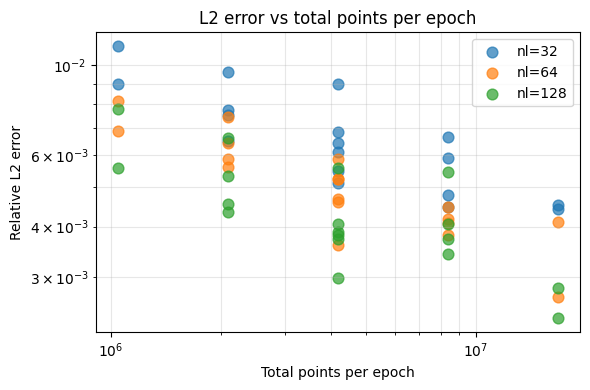

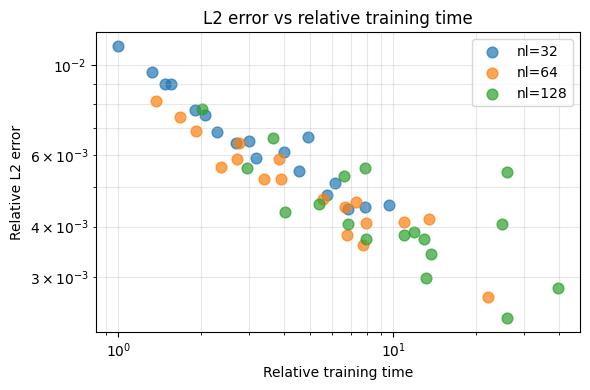

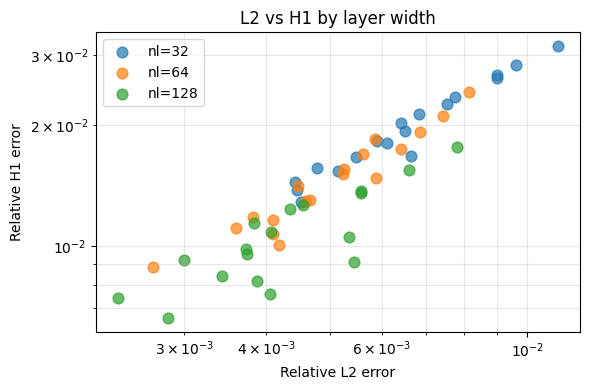

In [16]:
# --- Results analysis ---
df = pd.DataFrame(results).sort_values('L2_error').reset_index(drop=True)
df.index += 1
df.index.name = 'rank'

print("=" * 80)
print("PARAMETRIC STUDY RESULTS  (sorted by L2 error, best first)")
print("=" * 80)
display(df)

print("\n\nSummary statistics:")
print("-" * 40)
summary = df[['L2_error', 'H1_error', 'final_loss', 'time_s']].describe()
display(summary)

# Per-parameter group means
print("\n\nMean L2 error by layer width (nl):")
display(df.groupby('nl')[['L2_error', 'H1_error']].mean())

print("\nMean L2 error by number of residual blocks:")
display(df.groupby('n_blocks')[['L2_error', 'H1_error']].mean())

print("\nMean L2 error by total points (n_batches * n_points_batch):")
display(df.groupby('total_points')[['L2_error', 'H1_error']].mean())

# --- Plot 1: L2 error vs total points per epoch ---
fig1, ax1 = plt.subplots(1, 1, figsize=(6, 4))
for nl_val in param_grid['nl']:
    sub = df[df['nl'] == nl_val]
    ax1.scatter(sub['total_points'], sub['L2_error'], label=f'nl={nl_val}', s=60, alpha=0.7)
ax1.set_xlabel('Total points per epoch')
ax1.set_ylabel('Relative L2 error')
ax1.set_title('L2 error vs total points per epoch')
ax1.legend()
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig('Lshape_L2_vs_total_points.png', dpi=150)
save('Lshape_L2_vs_total_points.tex')
plt.show()

# --- Plot 2: L2 error vs relative training time (legend, not colorbar) ---
fig2, ax2 = plt.subplots(1, 1, figsize=(6, 4))
# Find the minimum training time to use as reference (relative time = 1)
min_time = df['time_s'].min()
for nl_val in param_grid['nl']:
    sub = df[df['nl'] == nl_val]
    relative_time = sub['time_s'] / min_time
    ax2.scatter(relative_time, sub['L2_error'], label=f'nl={nl_val}', s=60, alpha=0.7)
ax2.set_xlabel('Relative training time')
ax2.set_ylabel('Relative L2 error')
ax2.set_title('L2 error vs relative training time')
ax2.legend()
ax2.set_yscale('log')
ax2.set_xscale('log')
ax2.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig('Lshape_L2_vs_relative_training_time.png', dpi=150)
save('Lshape_L2_vs_relative_training_time.tex')
plt.show()

# Optional: L2 vs H1 by layer width (kept for reference)
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
for nl_val in param_grid['nl']:
    sub = df[df['nl'] == nl_val]
    ax.scatter(sub['L2_error'], sub['H1_error'], label=f'nl={nl_val}', s=60, alpha=0.7)
ax.set_xlabel('Relative L2 error')
ax.set_ylabel('Relative H1 error')
ax.set_title('L2 vs H1 by layer width')
ax.legend()
ax.set_xscale('log')
ax.set_yscale('log')
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig('parametric_study_results.png', dpi=150)
plt.show()